In [5]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
# =============================================================================
# Standard libraries
# =============================================================================
import os
import sys
import re
import gzip
import shutil
import pickle
from statistics import mode

# =============================================================================
# Third-party libraries
# =============================================================================
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import mmread
from scipy.sparse import csr_matrix
from sklearn import preprocessing, metrics
from sklearn.metrics.pairwise import euclidean_distances
from numpy.random import RandomState
import scanpy as sc
import torch
import torch_geometric
from torch_geometric.data import InMemoryDataset, Data, DataLoader
from torch_geometric.utils import *
from tqdm import tqdm
import warnings
# Insert project_dir into sys.path so local modules can be imported
sys.path.insert(0, 'E:\\VSCODE\\PrePR-CT\\Cell-Type-Specific-Graphs-main')
import utils
import model
from utils import *
from model import *
import torch

if torch.cuda.is_available():
    print("CUDA is available. GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available.")

# =============================================================================
# Warning configuration
# =============================================================================
warnings.simplefilter(action='ignore', category=RuntimeWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

# =============================================================================
# Configuration loader
# =============================================================================
'''def load_config(config_file):
    """Load configuration parameters from a YAML file."""
    with open(config_file, 'r') as f:
        config = yaml.safe_load(f)
    return config
    '''

def load_config(config_file):
    """Load configuration parameters from a YAML file."""
    with open(config_file, 'r', encoding='utf-8-sig') as f:
        config = yaml.safe_load(f)
    return config

CUDA is available. GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [ ]:
'''project_dir = r"E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main"

data_path = (
    r"E:\1Personal\New\科研起步"
    r"\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc"
)

dataset = "KOLF_ALPHA_HVG5000.h5ad"
full_dataset_path = os.path.join(data_path, dataset)

graphs_path = os.path.join(project_dir, "graphs")
graphs_data = "KOLF"
full_graphs_path = os.path.join(graphs_path, graphs_data)

full_save_path_results = os.path.join(
    project_dir, "Results", "KOLF_ALPHA"
)
full_save_path_models = os.path.join(
    project_dir, "model_checkpoints", "KOLF_ALPHA"
)

os.makedirs(full_save_path_results, exist_ok=True)
os.makedirs(full_save_path_models, exist_ok=True)

adata = sc.read_h5ad(full_dataset_path)

print(adata)
print("基因数:", adata.n_vars)
print("细胞数:", adata.n_obs)
print("基因名示例:", adata.var_names[:5].tolist())
print("obs 列:", adata.obs.columns.tolist())'''

AnnData object with n_obs × n_vars = 22608 × 5000
    obs: 'gRNA', 'n_gRNA', 'n_gRNA_UMIs', 'gene_target', 'celltype', 'perturbation_type', 'n_UMI_counts', 'n_genes', 'perturbed', 'channel', 'batch', 'perturbation', 'gene_target_ensembl_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier'
    var: 'gene_ids', 'feature_types', 'n_UMI_counts', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p'
基因数: 5000
细胞数: 22608
基因名示例: ['MIR1302-2HG', 'LINC02593', 'ENSG00000224969', 'TNFRSF18', 'INTS11']
obs 列: ['gRNA', 'n_gRNA', 'n_gRNA_UMIs', 'gene_target'

In [11]:
import os
import torch
import scanpy as sc
from scipy.sparse import issparse

# =============================================================================
# 1. Configuration
# =============================================================================

config_file = (
    r"E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main"
    r"\training\config_train_Kang.yaml"
)

config = load_config(config_file)

project_dir = config.get(
    "project_dir",
    r"E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main"
)

data_path = (
    r"E:\1Personal\New\科研起步"
    r"\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc"
)

dataset = "KOLF_ALPHA_HVG5000.h5ad"

save_path_results = os.path.join("Results", "KOLF_ALPHA")
save_path_models = os.path.join("model_checkpoints", "KOLF_ALPHA")

graphs_path = "graphs"
graphs_data = "KOLF"

multi_pert = config.get("multi_pert", True)

# KOLF 的 OOD 测试设置
testing_cell_type = ["KOLF"]
testing_drugs = ["DUX4"]

# 完整路径
full_data_path = data_path
full_dataset_path = os.path.join(full_data_path, dataset)

full_save_path_results = os.path.join(
    project_dir, save_path_results
)
full_save_path_models = os.path.join(
    project_dir, save_path_models
)
full_graphs_path = os.path.join(
    project_dir, graphs_path, graphs_data
)

os.makedirs(full_save_path_results, exist_ok=True)
os.makedirs(full_save_path_models, exist_ok=True)

params = config.get("params", {
    "hidden_channels": 128,
    "weight_decay": 1e-5,
    "in_head": 1,
    "learning_rate": -3,
    "num_epochs": 100,
    "batch_size": 256
})

print("Project Directory:", project_dir)
print("Dataset Path:", full_dataset_path)
print("Graphs Path:", full_graphs_path)
print("Results Save Path:", full_save_path_results)
print("Models Save Path:", full_save_path_models)
print("Training Parameters:", params)
print("Testing Cell Type:", testing_cell_type)
print("Testing Drugs:", testing_drugs)


# =============================================================================
# 2. Import Data
# =============================================================================

adata = sc.read_h5ad(full_dataset_path)

print(adata)
print("基因数:", adata.n_vars)
print("细胞数:", adata.n_obs)

# KOLF 当前数据没有原始 Kang 数据集的 cell_type / condition 列，
# 根据已有的 perturbed 和 gene_target 列恢复。
adata.obs["cell_type"] = "KOLF"
adata.obs["condition"] = "control"

mask_stim = (
    adata.obs["perturbed"].astype(str).to_numpy() == "True"
)

adata.obs.loc[mask_stim, "condition"] = (
    adata.obs.loc[mask_stim, "gene_target"].astype(str)
)

adata.obs["cov_drug"] = (
    adata.obs["cell_type"].astype(str)
    + "_"
    + adata.obs["condition"].astype(str)
)

print("条件数量:", adata.obs["cov_drug"].nunique())
print("Control 细胞数:", (adata.obs["condition"] == "control").sum())


# =============================================================================
# 3. Load the single KOLF coexpression graph
# =============================================================================

graph_path = os.path.join(
    full_graphs_path,
    "KOLF_A_4w_coexpr_graph.pkl"
)

if not os.path.exists(graph_path):
    raise FileNotFoundError(f"找不到图文件: {graph_path}")

# 与原始代码一致，优先使用 torch.load，而不是 pickle.load。
try:
    graph = torch.load(
        graph_path,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    graph = torch.load(graph_path, map_location="cpu")

cell_type_network = {"KOLF": graph}

print("KOLF 图加载成功")
print("图对象类型:", type(graph))
print("图节点数:", graph.num_nodes if hasattr(graph, "num_nodes") else "未知")


# =============================================================================
# 4. Matching Control & Treatment: compute graph node mean and variance
# =============================================================================

ctrl_data = adata[adata.obs["condition"] == "control"]

# 使用图中定义的基因索引
import numpy as np
import torch
from scipy.sparse import issparse

# 获取图节点对应的基因索引，并明确转换为整数
pos = cell_type_network["KOLF"].pos
if torch.is_tensor(pos):
    pos = pos.detach().cpu().numpy()

genes = np.asarray(pos).reshape(-1)

print("原始 genes dtype:", genes.dtype)
print("索引示例:", genes[:10])

# 如果是浮点数，先检查是否都是整数值，避免直接截断造成索引错误
if not np.issubdtype(genes.dtype, np.integer):
    genes_float = genes.astype(np.float64)
    if not np.all(np.isfinite(genes_float)) or not np.all(genes_float == np.floor(genes_float)):
        raise ValueError("graph.pos 中存在非整数索引，请检查图文件。")
    genes = genes_float.astype(np.int64)
else:
    genes = genes.astype(np.int64)

# 检查索引范围
if len(genes) == 0:
    raise ValueError("graph.pos 为空。")

if genes.min() < 0 or genes.max() >= adata.n_vars:
    raise ValueError(
        f"索引超出范围：min={genes.min()}, max={genes.max()}, "
        f"AnnData 基因数={adata.n_vars}"
    )

# 按原始流程提取 Control 细胞对应的图节点基因
ctrl_subset = ctrl_data[:, genes]

print("Control 子集形状:", ctrl_subset.shape)

# 只将 Control 子集转为稠密矩阵，避免把整个 AnnData 转为稠密矩阵
X_ctrl = ctrl_subset.X

if issparse(X_ctrl):
    X_ctrl = X_ctrl.toarray()

X_ctrl = torch.as_tensor(X_ctrl, dtype=torch.float32)

if X_ctrl.shape[0] < 2:
    raise ValueError(
        f"Control 细胞数只有 {X_ctrl.shape[0]}，"
        "至少需要 2 个细胞才能计算样本方差。"
    )

mean_expr = torch.mean(X_ctrl, dim=0)
var_expr = torch.var(X_ctrl, dim=0)

cell_type_network["KOLF"].x = torch.cat(
    [
        mean_expr.unsqueeze(1),
        var_expr.unsqueeze(1)
    ],
    dim=1
)

print("Control 子集形状:", tuple(X_ctrl.shape))
print("图节点特征形状:", tuple(cell_type_network["KOLF"].x.shape))
print("图节点特征 dtype:", cell_type_network["KOLF"].x.dtype)

del X_ctrl

Project Directory: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main
Dataset Path: E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc\KOLF_ALPHA_HVG5000.h5ad
Graphs Path: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\graphs\KOLF
Results Save Path: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\Results\KOLF_ALPHA
Models Save Path: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\model_checkpoints\KOLF_ALPHA
Training Parameters: {'hidden_channels': 64, 'weight_decay': 1e-05, 'in_head': 1, 'learning_rate': -3, 'num_epochs': 100, 'batch_size': 256}
Testing Cell Type: ['KOLF']
Testing Drugs: ['DUX4']
AnnData object with n_obs × n_vars = 22608 × 5000
    obs: 'gRNA', 'n_gRNA', 'n_gRNA_UMIs', 'gene_target', 'celltype', 'perturbation_type', 'n_UMI_counts', 'n_genes', 'perturbed', 'channel', 'batch', 'perturbation', 'gene_target_ensembl_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_coun

In [ ]:

# =============================================================================
# Prepare Data for Training
# =============================================================================

import os
import pickle
import numpy as np
import scanpy as sc
import torch
import tqdm

from torch_geometric.loader import DataLoader

# -------------------------------------------------------------------------
# 1. Load preprocessed cell data
# -------------------------------------------------------------------------

cells_path = os.path.join(data_path, "cells_KOLF.pkl")

if not os.path.exists(cells_path):
    raise FileNotFoundError(
        f"找不到预处理细胞文件：{cells_path}\n"
        "请先运行生成 cells_KOLF.pkl 的单元格。"
    )

with open(cells_path, "rb") as f:
    cell_all_Data = pickle.load(f)

print("预处理细胞总数：", len(cell_all_Data))


# -------------------------------------------------------------------------
# 2. Identify OOD perturbations
# -------------------------------------------------------------------------

# KOLF 数据中 cell_type 应为 KOLF；
# condition 为 control 或具体的 gene_target。
adata.obs["cell_type"] = adata.obs["cell_type"].astype(str)
adata.obs["condition"] = adata.obs["condition"].astype(str)

adata.obs["cov_drug"] = (
    adata.obs["cell_type"] + "_" + adata.obs["condition"]
)

testing_cov_drug = (
    adata.obs.loc[
        adata.obs["condition"].isin(testing_drugs)
        & adata.obs["cell_type"].isin(testing_cell_type),
        "cov_drug"
    ]
    .drop_duplicates()
    .tolist()
)

print("OOD 测试扰动：", testing_cov_drug)

if not testing_cov_drug:
    raise ValueError(
        "没有找到 OOD 测试扰动。请检查 testing_drugs、"
        "testing_cell_type 和 adata.obs 中的实际取值。"
    )

# -------------------------------------------------------------------------
# 3. Partition training and OOD cells
# -------------------------------------------------------------------------

# 先检查 pkl 中是否包含这些 OOD 条件
available_cov_drug = {
    sample.cov_drug for sample in cell_all_Data
}

missing_ood = [
    cov for cov in testing_cov_drug
    if cov not in available_cov_drug
]

if missing_ood:
    raise ValueError(
        f"以下 OOD 条件在 cells_KOLF.pkl 中没有对应样本：{missing_ood}"
    )

cells_ood = [
    sample for sample in cell_all_Data
    if sample.cov_drug in testing_cov_drug
]

cells_train = [
    sample for sample in cell_all_Data
    if sample.cov_drug not in testing_cov_drug
]

print("Cells (train, OOD):", len(cells_train), len(cells_ood))

if not cells_train or not cells_ood:
    raise ValueError("训练集或 OOD 测试集为空，请检查条件划分。")

# -------------------------------------------------------------------------
# 4. Create training DataLoader
# -------------------------------------------------------------------------

train_dataloader = DataLoader(
    cells_train,
    batch_size=params["batch_size"],
    shuffle=True
)

# -------------------------------------------------------------------------
# 5. Initialize GNN
# -------------------------------------------------------------------------

torch.manual_seed(42)

model = GNN(
    total_genes=len(adata.var),
    num_perts=110,
    act_fct="Sigmoid",
    hidden_channels=params["hidden_channels"],
    in_head=params["in_head"],
    multi_pert=multi_pert
).to(device).float()

# 统一训练样本和图的 dtype
for data in cells_train:
    if getattr(data, "x", None) is not None:
        data.x = data.x.float()
    if getattr(data, "y", None) is not None:
        data.y = data.y.float()

for graph in cell_type_network.values():
    if getattr(graph, "x", None) is not None:
        graph.x = graph.x.float()

print("模型：", next(model.parameters()).dtype)
print("训练数据 x：", cells_train[0].x.dtype)
print("训练数据 y：", cells_train[0].y.dtype)
print("图节点特征：", cell_type_network["KOLF"].x.dtype)

# -------------------------------------------------------------------------
# 6. Train model
# -------------------------------------------------------------------------

model = train(
    model=model,
    num_epochs=params["num_epochs"],
    lr=10 ** params["learning_rate"],
    weight_decay=params["weight_decay"],
    multi_pert=multi_pert,
    cell_type_network=cell_type_network,
    train_loader=train_dataloader
)

# -------------------------------------------------------------------------
# 7. Save and reload trained model
# -------------------------------------------------------------------------

model_path = os.path.join(
    full_save_path_models,
    "KOLF_model.pt"
)

torch.save(model.state_dict(), model_path)
print("模型已保存：", model_path)

model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

print("模型权重重新加载成功")




预处理细胞总数： 20752
OOD 测试扰动： ['KOLF_DUX4']
Cells (train, OOD): 20735 17
模型： torch.float32
训练数据 x： torch.float32
训练数据 y： torch.float32
图节点特征： torch.float32
Training Starts


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/81 [00:00<?, ?it/s]

Epoch 0, train loss: 23.081391275664906


  0%|          | 0/81 [00:00<?, ?it/s]

...

  0%|          | 0/81 [00:00<?, ?it/s]

Epoch 98, train loss: 22.301030100127797


  0%|          | 0/81 [00:00<?, ?it/s]

Epoch 99, train loss: 22.30274631358959
模型已保存： E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\model_checkpoints\KOLF_ALPHA\KOLF_model.pt


UnpicklingError: Weights only load failed. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution.Do it only if you get the file from a trusted source. WeightsUnpickler error: Unsupported class torch.nn.parameter.UninitializedParameter

In [15]:
# 只加载已经训练好的权重，不重新训练
import torch
import os

model_path = os.path.join(
    full_save_path_models,
    "KOLF_model.pt"
)

try:
    state_dict = torch.load(
        model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(state_dict)
    model = model.to(device).float()
    model.eval()

    print("✅ 已成功加载模型权重，无需重新训练！")

except Exception as e:
    print("❌ 加载失败：", repr(e))
    raise

✅ 已成功加载模型权重，无需重新训练！


In [ ]:
# Notebook 临时修复：将 KOLF 图的基因索引转为整数
cell_type_network["KOLF"].pos = (
    cell_type_network["KOLF"].pos.to(torch.long)
)

print("修复后 dtype：", cell_type_network["KOLF"].pos.dtype)
print("前 10 个索引：", cell_type_network["KOLF"].pos[:10])

100%|██████████| 1/1 [00:00<00:00,  1.19it/s]

KOLF_DUX4: 扰动细胞 17, Control 细胞 1856, 显著 DEG 数 100
成功生成 DEG 的 OOD 条件： ['KOLF_DUX4']
模型和 OOD 数据的 dtype 已统一为 float32
OOD 推理样本数： 17
-------------------------------------------- Mean Expression Prediction --------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

KOLF_DUX4  mse:  0.14041483
R² value for predicting the **mean** expression of all genes for perturbation 'KOLF_DUX4': 0.9359
R² value for predicting the **mean** of the top 100 DEGs for perturbation 'KOLF_DUX4': 0.0000
-------------------------------------------- Std Expression Prediction --------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

KOLF_DUX4  mse:  0.14041483
R² value for predicting the **standard deviation** expression of all genes for perturbation 'KOLF_DUX4': -0.3308
R² value for predicting the **standard deviation** of the top 100 DEGs for perturbation 'KOLF_DUX4': 0.0000
KOLF 训练和 OOD 推理流程结束。


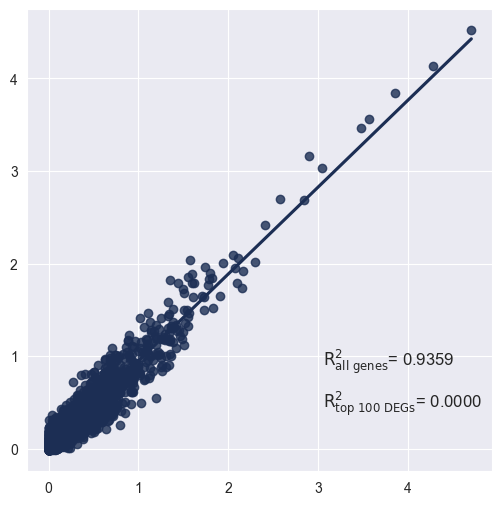

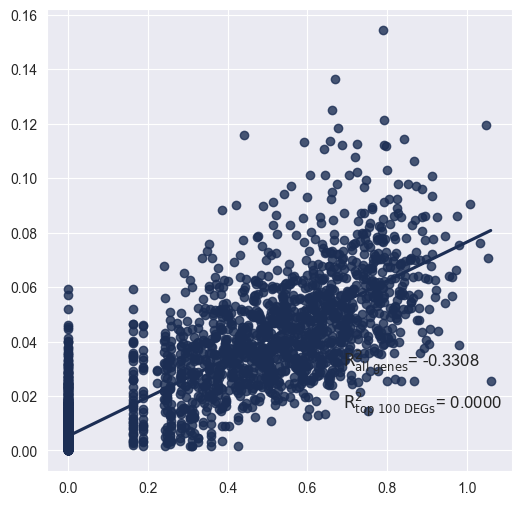

In [23]:
# =============================================================================
# Prepare DEG dictionary for OOD perturbations
# =============================================================================

degs_dict = {}

for cov_drug in tqdm.tqdm(testing_cov_drug):
    # KOLF_DUX4 -> cell type KOLF, perturbation DUX4
    ood_cell, testing_drug = cov_drug.split("_", 1)

    genes = cell_type_network[ood_cell].pos
    if torch.is_tensor(genes):
        genes = genes.detach().cpu().numpy()

    genes = np.asarray(genes).reshape(-1)

    if not np.issubdtype(genes.dtype, np.integer):
        genes_float = genes.astype(np.float64)
        if (
            not np.all(np.isfinite(genes_float))
            or not np.all(genes_float == np.floor(genes_float))
        ):
            raise ValueError(f"{cov_drug} 的图基因索引不是整数。")
        genes = genes_float.astype(np.int64)
    else:
        genes = genes.astype(np.int64)

    # 取该扰动和对应 Control 的图节点基因
    control_cov = f"{ood_cell}_control"

    adata_cov = adata[
        adata.obs["cov_drug"].isin([cov_drug, control_cov]),
        genes
    ].copy()

    group_counts = adata_cov.obs["cov_drug"].value_counts()

    if cov_drug not in group_counts or control_cov not in group_counts:
        print(f"跳过 {cov_drug}：扰动组或 Control 组缺失。")
        continue

    if group_counts[cov_drug] < 2 or group_counts[control_cov] < 2:
        print(f"跳过 {cov_drug}：某组细胞数不足 2。")
        continue

    # 原始流程：t-test + Benjamini-Hochberg 校正
    sc.tl.rank_genes_groups(
        adata_cov,
        groupby="cov_drug",
        rankby_abs=True,
        method="t-test",
        corr_method="benjamini-hochberg",
        reference=control_cov,
        n_genes=adata_cov.n_vars
    )

    dedf = sc.get.rank_genes_groups_df(
        adata_cov,
        group=cov_drug
    )

    dedf = dedf.loc[dedf["pvals_adj"] < 0.05].copy()

    DEGs_name = rank_genes(dedf)

    mask = adata_cov.var_names.isin(DEGs_name)
    indices_np = np.where(mask)[0]

    degs_dict[cov_drug] = indices_np

    print(
        f"{cov_drug}: 扰动细胞 {group_counts[cov_drug]}, "
        f"Control 细胞 {group_counts[control_cov]}, "
        f"显著 DEG 数 {len(indices_np)}"
    )

print("成功生成 DEG 的 OOD 条件：", list(degs_dict.keys()))


# =============================================================================
# OOD inference
# =============================================================================

ood_loader_all = DataLoader(
    cells_ood,
    batch_size=params["batch_size"],
    shuffle=True
)

for data in cells_ood:
    if getattr(data, "x", None) is not None:
        data.x = data.x.float()
    if getattr(data, "y", None) is not None:
        data.y = data.y.float()

for graph in cell_type_network.values():
    if getattr(graph, "x", None) is not None:
        graph.x = graph.x.float()

model = model.float()

print("模型和 OOD 数据的 dtype 已统一为 float32")
print("OOD 推理样本数：", len(cells_ood))


# -------------------------------------------------------------------------
# 8. Predict mean expression
# -------------------------------------------------------------------------

print(
    "-------------------------------------------- "
    "Mean Expression Prediction "
    "--------------------------------------------"
)

Inference_multi_pert(
    cell_type_network,
    model,
    full_save_path_results,
    ood_loader_all,
    adata,
    degs_dict=degs_dict,
    mean_or_std=True,
    plot=True,
    multi_pert=multi_pert
)


# -------------------------------------------------------------------------
# 9. Predict standard deviation expression
# -------------------------------------------------------------------------

print(
    "-------------------------------------------- "
    "Std Expression Prediction "
    "--------------------------------------------"
)

Inference_multi_pert(
    cell_type_network,
    model,
    full_save_path_results,
    ood_loader_all,
    adata,
    degs_dict=degs_dict,
    mean_or_std=False,
    plot=True,
    multi_pert=multi_pert
)

print("KOLF 训练和 OOD 推理流程结束。")


修复后 dtype： torch.int64
前 10 个索引： tensor([ 2,  3,  4,  5,  7,  8,  9, 10, 14, 15])


In [ ]:
# 统计每个真实扰动靶基因的细胞数
gene_counts = (
    adata.obs.loc[
        adata.obs["condition"] == "perturbed",
        "gene_target"
    ]
    .value_counts()
)

# 选择细胞数最多的前 20 个靶基因
testing_genes = gene_counts.head(20).index.tolist()

print("测试靶基因数量:", len(testing_genes))
print(testing_genes)
print(gene_counts.loc[testing_genes])

测试靶基因数量: 20
['KDM5C', 'ZFP41', 'VDR', 'ESR1', 'LARP1', 'ZFP3', 'HNF1B', 'HNF4A', 'TBXT', 'ZFP28', 'BMAL2', 'ELOC', 'ZFP37', 'DUX4', 'ASNS', 'ADNP2', 'ARHGAP35', 'KMT5C', 'UBTFL1', 'THAP12']
gene_target
KDM5C       23
ZFP41       22
VDR         22
ESR1        20
LARP1       19
ZFP3        19
HNF1B       19
HNF4A       18
TBXT        18
ZFP28       17
BMAL2       17
ELOC        17
ZFP37       17
DUX4        17
ASNS        17
ADNP2       17
ARHGAP35    17
KMT5C       17
UBTFL1      16
THAP12      16
Name: count, dtype: int64


In [ ]:
'''# 查看 KOLF A 中每个扰动靶基因的细胞数量
gene_counts = (
    adata.obs.loc[
        adata.obs["condition"] == "perturbed", "gene_target"
    ]
    .value_counts()
)

print("扰动靶基因数量:", len(gene_counts))
print("\n细胞数最多的前 30 个靶基因：")
print(gene_counts.head(30))

# 暂时不指定测试基因，先检查训练样本是否已准备好
testing_genes = []
testing_cov_drug = []'''

'# 查看 KOLF A 中每个扰动靶基因的细胞数量\ngene_counts = (\n    adata.obs.loc[\n        adata.obs["condition"] == "perturbed", "gene_target"\n    ]\n    .value_counts()\n)\n\nprint("扰动靶基因数量:", len(gene_counts))\nprint("\n细胞数最多的前 30 个靶基因：")\nprint(gene_counts.head(30))\n\n# 暂时不指定测试基因，先检查训练样本是否已准备好\ntesting_genes = []\ntesting_cov_drug = []'

In [6]:
import torch

print("===== 模型参数 dtype =====")
for name, param in model.named_parameters():
    print(name, param.dtype)
    break

print("\n===== 训练数据 dtype =====")
for batch in train_dataloader:
    print("batch 类型:", type(batch))

    if hasattr(batch, "to_dict"):
        batch = batch.to_dict()

    if isinstance(batch, dict):
        for key, value in batch.items():
            if torch.is_tensor(value):
                print(key, value.dtype, tuple(value.shape))
            elif isinstance(value, (list, tuple)):
                for i, item in enumerate(value[:3]):
                    if torch.is_tensor(item):
                        print(f"{key}[{i}]", item.dtype, tuple(item.shape))
    break

===== 模型参数 dtype =====


AttributeError: module 'model' has no attribute 'named_parameters'

In [ ]:
# ===== 修复 PrePR-CT 训练数据的 dtype =====
import torch

def fix_dataloader_dtype(dataloader):
    """将 PyTorch Geometric 数据中的浮点特征统一为 float32。"""
    for data in dataloader.dataset:
        if hasattr(data, "x") and data.x is not None:
            data.x = data.x.float()

        if hasattr(data, "y") and data.y is not None:
            data.y = data.y.float()

    return dataloader


train_dataloader = fix_dataloader_dtype(train_dataloader)

# 检查修复结果
batch = next(iter(train_dataloader))
print("x dtype:", batch.x.dtype)
print("y dtype:", batch.y.dtype)
print("模型 dtype:", next(model.parameters()).dtype)

x dtype: torch.float32
y dtype: torch.float32
模型 dtype: torch.float32


In [ ]:
# ===== 定位 PrePR-CT 中 dtype 不匹配的具体线性层 =====
import torch

dtype_debug_hooks = []

def debug_linear_dtype(module, inputs):
    weight = getattr(module, "weight", None)

    if weight is None:
        return

    for x in inputs:
        if torch.is_tensor(x) and x.is_floating_point():
            if x.dtype != weight.dtype:
                print("\n发现 dtype 不一致！")
                print("层名称：", module)
                print("输入 dtype：", x.dtype)
                print("输入 shape：", tuple(x.shape))
                print("权重 dtype：", weight.dtype)
                print("权重 shape：", tuple(weight.shape))

                raise RuntimeError(
                    "已定位 dtype 不匹配的线性层；"
                    "请根据上面的信息修复源头。"
                )

# 移除之前注册的钩子，避免旧钩子干扰诊断
for hook in dtype_hooks:
    hook.remove()
dtype_hooks.clear()

# 在每个 Linear 层执行前检查输入
for name, layer in model.named_modules():
    if isinstance(layer, torch.nn.Linear):
        hook = layer.register_forward_pre_hook(debug_linear_dtype)
        dtype_debug_hooks.append(hook)

print("已为", len(dtype_debug_hooks), "个 Linear 层启用 dtype 诊断。")

已为 3 个 Linear 层启用 dtype 诊断。


In [ ]:
import torch
import torch.nn.functional as F
import traceback

# 保存原始函数
_original_linear = F.linear

def debug_linear(input, weight, bias=None):
    if input.dtype != weight.dtype:
        print("\n===== 定位到真正的 dtype 冲突 =====")
        print("input dtype:", input.dtype)
        print("input shape:", tuple(input.shape))
        print("weight dtype:", weight.dtype)
        print("weight shape:", tuple(weight.shape))
        print("bias dtype:", bias.dtype if bias is not None else None)
        traceback.print_stack(limit=8)
        raise RuntimeError(
            f"F.linear dtype mismatch: input={input.dtype}, "
            f"weight={weight.dtype}"
        )

    return _original_linear(input, weight, bias)

# 安装诊断包装
F.linear = debug_linear

print("诊断已开启。现在重新运行原来的训练单元格。")

诊断已开启。现在重新运行原来的训练单元格。


In [ ]:
import torch
import torch.nn.functional as F

F.linear = _original_linear

In [ ]:
import inspect
import torch

for name, module in model.named_modules():
    if isinstance(module, torch.nn.Linear):
        try:
            print(f"层名称: {name}")
            print(f"定义文件: {inspect.getfile(type(module))}")
            print(f"权重类型: {module.weight.dtype}")
            print("-" * 40)
        except (TypeError, OSError):
            pass

层名称: embd_pert.network.0
定义文件: e:\Anaconda\envs\preprct\lib\site-packages\torch\nn\modules\linear.py
权重类型: torch.float32
----------------------------------------
层名称: lin_predict.network.0
定义文件: e:\Anaconda\envs\preprct\lib\site-packages\torch\nn\modules\linear.py
权重类型: torch.float32
----------------------------------------
层名称: lin_predict.network.2
定义文件: e:\Anaconda\envs\preprct\lib\site-packages\torch\nn\modules\linear.py
权重类型: torch.float32
----------------------------------------
